Name: Ryan Jamison
Computing ID: asu6pt

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest
from scipy import stats
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import statsmodels.api as sm
from statsmodels.stats.power import TTestIndPower
from scipy.stats import norm

In [2]:
peng = pd.read_csv('../../Git/data/penguins.csv')

<Axes: xlabel='island', ylabel='body_mass_g'>

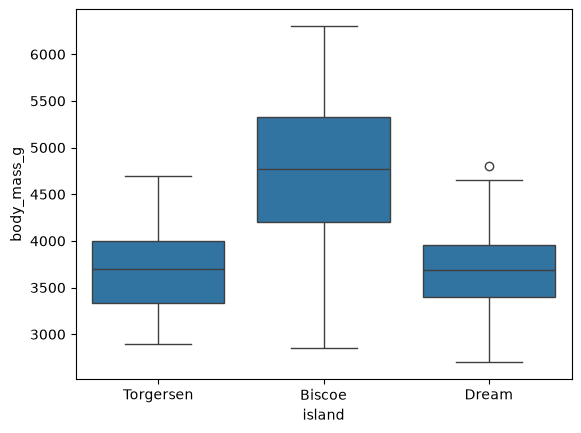

In [3]:
sns.boxplot(data = peng, x='island', y='body_mass_g')

#### Dream and Torgensen islands have similar distributions of penguin weights, including their median, max, and min. Biscoe however has more variance with a much higher median and max, but similar minimum weight in grams. 

In [4]:
peng["is_large"] = peng["body_mass_g"] > peng["body_mass_g"].median()

In [5]:
biscoe = peng.loc[peng['island'] == 'Biscoe']
large_biscoe = biscoe['is_large'].mean()
large = peng['is_large'].mean()
print(f'{((large_biscoe) * 100):.2f} percent of penguins on Biscoe Island are considered large.')
print(f'{(large) * 100:.2f} percent of penguins across all islands are considered large.')

77.98 percent of penguins on Biscoe Island are considered large.
48.26 percent of penguins across all islands are considered large.


In [6]:
peng["is_biscoe"] = peng["island"] == "Biscoe"
x = pd.crosstab(peng["is_biscoe"], peng["is_large"])
print(x)

# Not familiar with statsmodels, Gemini assisted with the next 3 lines
count = [x.loc[True, True], x.loc[False, True]] 
nobs = [x.loc[True].sum(), x.loc[False].sum()] 
z, p = proportions_ztest(count, nobs) 

print(f"Z statistic: {z:.2f}")
print(f"P value: {p:.2e}")

is_large   False  True 
is_biscoe              
False        141     35
True          37    131
Z statistic: 10.78
P value: 4.39e-27


#### After running the z test, there's significant evidence that the penguins on Biscoe island are larger than the penguins from all three islands. 

<Axes: xlabel='island', ylabel='count'>

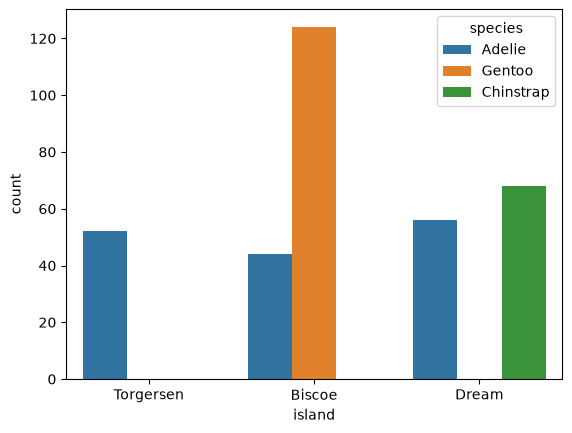

In [7]:
sns.countplot(data=peng, x="island", hue="species")

#### Seeing that Gentoo penguins live exclusively on Biscoe Island, I think it's reasonable to assume that they're a larger species of penguin and contribute to the numbers being so mismatched across the islands. 

is_large  False  True 
island                
False        84     24
True         35      9
Adelie Z-statistic: -0.24
Adelie P-value: 8.11e-01


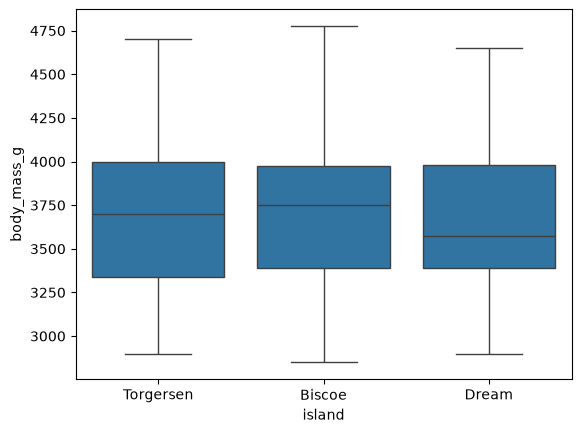

In [8]:
#Choosing Adelie since they live on every island
adelie = peng.loc[peng['species'] == 'Adelie']
sns.boxplot(data = adelie, x='island', y='body_mass_g')

ct_adelie = pd.crosstab(adelie["island"] == "Biscoe", adelie["is_large"])
print(ct_adelie)

count_adelie = [ct_adelie.loc[True, True], ct_adelie.loc[False, True]]
nobs_adelie = [ct_adelie.loc[True].sum(), ct_adelie.loc[False].sum()]
z_stat_adelie, p_val_adelie = proportions_ztest(count_adelie, nobs_adelie)

print(f"Adelie Z-statistic: {z_stat_adelie:.2f}")
print(f"Adelie P-value: {p_val_adelie:.2e}")

#### Testing for only Adelie across all 3 islands turns up a much different result. As shown by the plot, the weights across the three islands are very similar and the z test backs it up, not giving any reason to reject the null hypothesis that weight distributions are the same across the three islands. 

#### Start Activity 2

In [9]:
response = pd.read_csv('../../Git/data/DS6021-Fall26-Anonymized.csv')

#from lab 0
col_mapping = {
    'Timestamp': 'timestamp',
    'What was your undergraduate major?': 'major',
    'What type of phone do you have?': 'phone_type',
    'How many years ago did you receive your undergraduate degree?': 'years_since_degree',
    'How many hours do you sleep in a typical night?': 'sleep_hours',
    'Rate your proficiency with git/github': 'git_prof',
    'Rate your proficiency with Python': 'python_prof',
    'Have you ever used SQL?': 'used_sql',
    'What is your favorite sport to watch on tv?': 'fav_sport',
    'What is your ideal outdoor temperature (in Fahrenheit)?': 'ideal_temp',
    'How many US states have you visited?': 'states_visited',
    'What is your favorite season?': 'fav_season'
}
response.rename(columns=col_mapping, inplace=True)

#also my work from lab 0, sleep needs cleaning
def clean_sleep(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).split('-')[0].strip()
    return pd.to_numeric(val_str, errors='coerce')

response['sleep_hours'] = response['sleep_hours'].apply(clean_sleep)

response

,timestamp,major,phone_type,years_since_degree,sleep_hours,git_prof,python_prof,used_sql,fav_sport,ideal_temp,states_visited,fav_season
0,8/25/2026 8:20:43,Psychology,iPhone,4-6 years,8.0,3,2,Yes,F1 motorsport,70,8,Fall
1,8/25/2026 9:35:51,Statistics,iPhone,1-3 years,8.0,3,4,Yes,NaN,70,16,Fall
2,8/25/2026 13:43:23,Economics-Business and Applied Mathematics,iPhone,< 1 year,8.0,3,3,No,Baseball,70,27,Fall
3,8/25/2026 15:11:38,Data Science (concentration in Computer Science),iPhone,< 1 year,8.0,3,4,Yes,Football (go Bears!),73,9,Fall
4,8/25/2026 15:26:11,Math and Physics,iPhone,1-3 years,8.0,2,4,Yes,Figure Skating,73,26,Fall
...,...,...,...,...,...,...,...,...,...,...,...,...
81,8/26/2026 11:42:57,Bioinformatics and Biology,iPhone,< 1 year,5.0,2,3,No,Football,40 degrees,16,Winter
82,8/26/2026 11:44:34,Computer Science,iPhone,< 1 year,4.0,3,3,Yes,Soccer,75,1,Summer
83,8/26/2026 11:48:23,IT-Concentration in Data Science,iPhone,1-3 years,6.5,3,3,Yes,Soccer and Fustal,68,5,Spring
84,8/26/2026 11:52:24,Data Science,iPhone,< 1 year,7.0,4,4,No,Football,63,"If I had to guess, 23",Fall


<Axes: xlabel='experience_binned', ylabel='sleep_hours'>

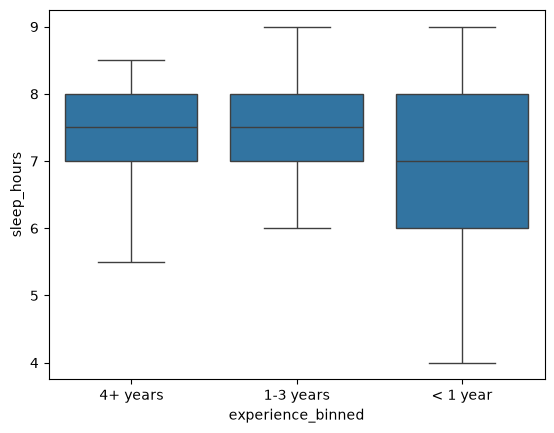

In [10]:
category_map = {"< 1 year": "< 1 year", "1-3 years": "1-3 years", "4-6 years": "4+ years", "7-10 years": "4+ years"}
response["experience_binned"] = response["years_since_degree"].map(category_map)

sns.boxplot(data=response, x='experience_binned', y='sleep_hours')

In [11]:
target_col = "sleep_hours"

g1 = response[response["experience_binned"] == "< 1 year"][target_col].dropna()
g2 = response[response["experience_binned"] == "1-3 years"][target_col].dropna()
g3 = response[response["experience_binned"] == "4+ years"][target_col].dropna()

#Gemini assisted with the syntax for the next line
stat_lev, p_lev = stats.levene(g1, g2, g3)
print(f"Levene's Test p-value: {p_lev:.2f}")

stat_f, p_f = stats.f_oneway(g1, g2, g3)
print(f"ANOVA p-value: {p_f:.2f}")

Levene's Test p-value: 0.89
ANOVA p-value: 0.09


#### Both p values are above the standard alpha of 0.05 so we fail to reject both null hypotheses. For the Levene test this means that the group variances are decently equal enough to proceed with ANOVA. For the regular ANOVA this means that there is no significant difference in average responses across the three experience bins.

#### 2.3.a) Putting numerical data into bins decreases the statistical power of tests like ANOVA
#### 2.3.b) No, you're still putting numerical data into categories
#### 2.3.c) Allow them to enter their own amount while also asking to keep the responses without words for easier cleaning

#### 2.4) In a sense, yes this is a good dataframe to begin working on data cleaning. The responses, especially the open ended ones, can be ambiguous and have no strict format. For example, many students tried to justify why they slept the amount they did or entered a range (which I was guilty of too). The only downside is that the dataset is relatively small, but that may also be a plus since it's our first assignment, it could go either way.

#### Start Activity 3

In [12]:
drug = pd.read_csv('../../Git/data/Clinical_trial.csv')
drug

,Drug,Pain_Rating
0,A,4
1,A,5
2,A,4
3,A,3
4,A,2
5,A,4
6,A,3
7,A,4
8,A,4
9,B,6


<Axes: xlabel='Drug', ylabel='Pain_Rating'>

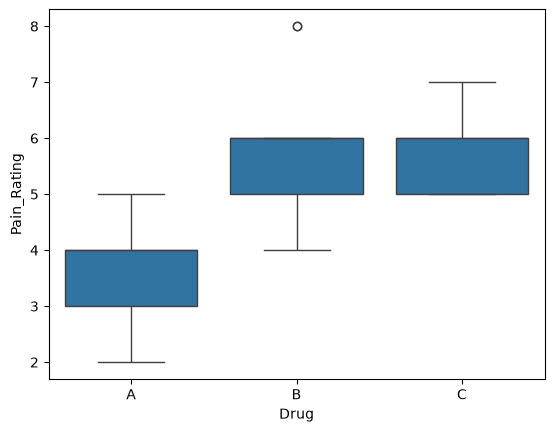

In [13]:
sns.boxplot(data=drug, x='Drug', y='Pain_Rating')

#### The graph shows drugs B and C with a 25th and 75th percentile of pain rating at 5 and 6 respectively, but the median isn't showing due to the discrete nature of the survey data. Graph A shows early signs of being better for migraine relief, with similar variance to drugs B and C.

In [14]:
# The null hypothesis is that all drugs perform the same

levene_stat, levene_p = stats.levene(*[group["Pain_Rating"].dropna() for _, group in drug.groupby("Drug")])
print(f"Levene's Test p-value: {levene_p:.2f}")

model = ols("Pain_Rating ~ C(Drug)", data=drug).fit()
anova_table = sm.stats.anova_lm(model)
print("\nANOVA Table:")
print(anova_table)

if anova_table["PR(>F)"].iloc[0] < 0.05:
    tukey = pairwise_tukeyhsd(endog=drug["Pain_Rating"], groups=drug["Drug"], alpha=0.05)
    print("\nPairwise Comparisons (Tukey HSD):")
    print(tukey)

Levene's Test p-value: 0.21

ANOVA Table:
            df     sum_sq    mean_sq         F    PR(>F)
C(Drug)    2.0  28.222222  14.111111  11.90625  0.000256
Residual  24.0  28.444444   1.185185       NaN       NaN

Pairwise Comparisons (Tukey HSD):
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     A      B   2.1111 0.0011  0.8295 3.3927   True
     A      C   2.2222 0.0006  0.9406 3.5038   True
     B      C   0.1111 0.9745 -1.1705 1.3927  False
---------------------------------------------------


#### 3.2) 
#### The null hypothesis is that all drugs perform the same at reducing migraine pain, while the alternate hypothesis is that at least 1 performs better than the others. 

#### After verifying that the variances are similar enough to run ANOVA with the Levene test, an ordinary least squares regression is run to see if all drugs behave the same, which they don't due to the tiny PR(>F).

#### After determining that all drugs don't reduce pain the same and that at least one performs better, I ran the Tukey test to determine which one. Since the p-values are below 0.05 for both test runs with Drug A, we reject the null that A reduces pain as well as B or C and conclude that it performs better than both of them. 

#### 3.3)
#### My guess is that the model would take in patient factors about their health as inputs and predict how well the drug will help reduce migraine pain along the same 10 point scale. 

#### Statistical modeling would more be used to verfy results and calculate p-values while prediction would be used to estimate how well a patient will respond to a drug, or more likely how much money they can charge to maximize profits. 

#### Start Activity 4

In [15]:
#4.1
npg = 1200
a = 0.05
power = 0.80
sd = 4.0

power_analysis = TTestIndPower()

# gemini helped with the syntax of the arguments
cohens_d = power_analysis.solve_power(effect_size=None, nobs1=npg, alpha=a, power=power, ratio=1.0, alternative="two-sided")

mde_minutes = cohens_d * sd

print(f"Standardized Effect Size: {cohens_d:.3f}")
print(f"Minimum Detectable Effect: {mde_minutes:.3f}")

Standardized Effect Size: 0.114
Minimum Detectable Effect: 0.458


#### 4.2)
#### Not yet, although enough time has passed the minimum detectable effect, it does so just barely. I would wait another day or two before concluding the test, just to be more confident in switching over to version B.

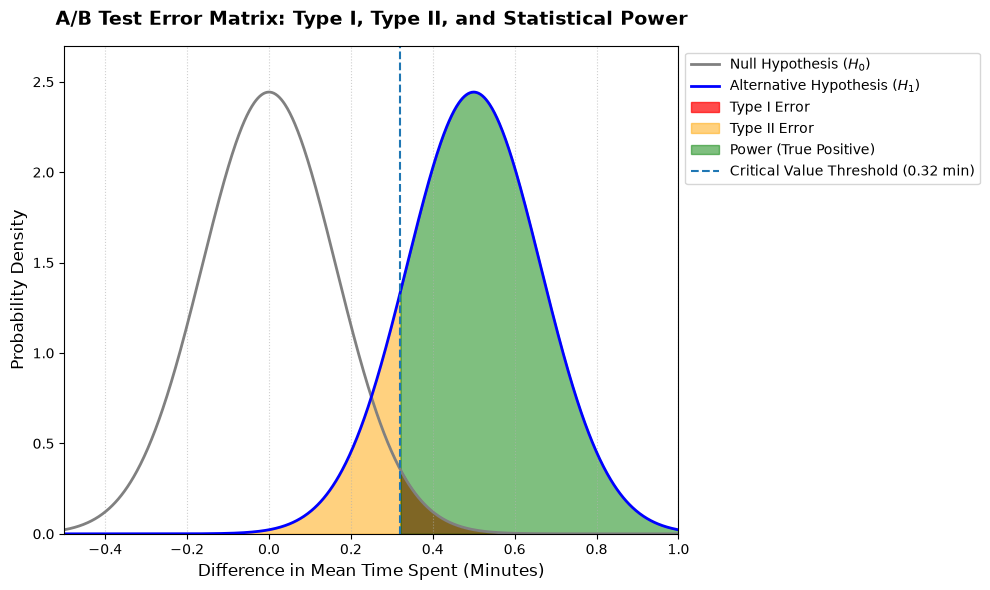

In [16]:
#gemini assisted in the code for the visualization
mean_diff_H0 = 0.0
mean_diff_H1 = 0.5 
se_diff = np.sqrt((4.0**2)/1200 + (4.0**2)/1200) 

x = np.linspace(-0.5, 1.0, 1000)
y_H0 = norm.pdf(x, mean_diff_H0, se_diff)
y_H1 = norm.pdf(x, mean_diff_H1, se_diff) 
crit_val = norm.ppf(0.975, loc=mean_diff_H0, scale=se_diff)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(x, y_H0, color='gray', linewidth=2, label='Null Hypothesis ($H_0$)')
ax.plot(x, y_H1, color='blue', linewidth=2, label='Alternative Hypothesis ($H_1$)')

x_alpha = x[x >= crit_val]
ax.fill_between(x_alpha, norm.pdf(x_alpha, mean_diff_H0, se_diff), 
                color='red', alpha=0.7, label='Type I Error')

x_beta = x[x <= crit_val]
ax.fill_between(x_beta, norm.pdf(x_beta, mean_diff_H1, se_diff), 
                color='orange', alpha=0.5, label='Type II Error')


x_power = x[x >= crit_val]
ax.fill_between(x_power, norm.pdf(x_power, mean_diff_H1, se_diff), 
                color='green', alpha=0.5, label='Power (True Positive)')

ax.axvline(crit_val, linestyle='--', linewidth=1.5, 
           label=f'Critical Value Threshold ({crit_val:.2f} min)')

ax.set_title("A/B Test Error Matrix: Type I, Type II, and Statistical Power", 
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Difference in Mean Time Spent (Minutes)", fontsize=12)
ax.set_ylabel("Probability Density", fontsize=12)
ax.set_xlim(-0.5, 1.0)
ax.set_ylim(0, 2.7)
ax.legend(loc='upper left', fontsize=10, bbox_to_anchor=(1, 1))
ax.grid(axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

- There is a 2.5% chance we deploy version B by a fluke chance (type 1 error in the right tail of the uncolored curve)
- The dashed line at 0.32 is the value where we need the difference in time (minutes) to be greater than to show that version B isn't a fluke
- Because the observed difference in mean time spent is large compared to the critical value, the statistical power is large